# VIDEO TO SAM 2 MASKS

## IMPORTS

In [1]:
%matplotlib widget

from utils import *    
import json
import shutil
import torch
from sam2.build_sam import build_sam2_video_predictor

## Settings

In [2]:
FIRST = 306
COUNT = 100
STEP = 1

#SAM 2 model
CHECKPOINT = "../checkpoints/sam2.1_hiera_small.pt"
CONFIG = "configs/sam2.1/sam2.1_hiera_s.yaml"

## Read video

frames in the video : 1099
shape : (240, 360, 3)


(<Figure size 1000x400 with 1 Axes>,
 array([[<Axes: title={'center': 'frame 306'}>]], dtype=object))

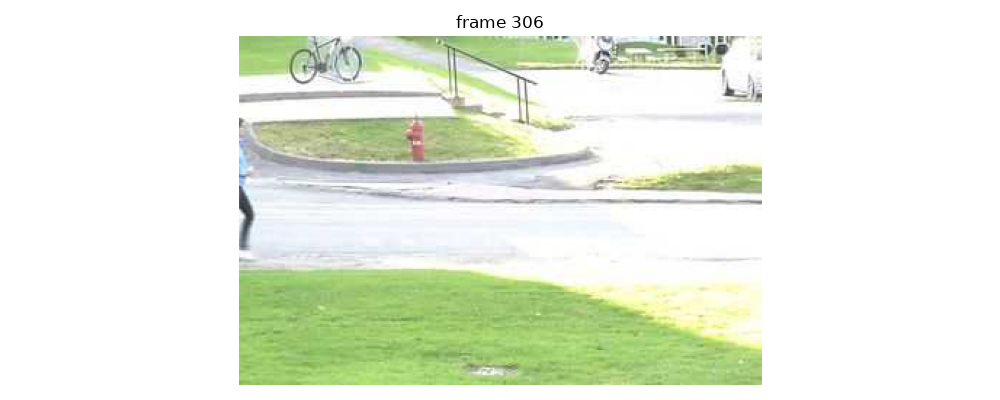

In [3]:
nb_frames = count_frames(SRC)
print("frames in the video :", nb_frames)

image = read_frame(SRC, FIRST)
print("shape :", image.shape)
imshow(image, f"frame {FIRST}")

## EXTRACT FRAMES

In [4]:
#start from empty folder, remove old
shutil.rmtree(FRAMES_dir, ignore_errors=True)
os.makedirs(FRAMES_dir)

for i in range(COUNT) : 
    k = FIRST + i*STEP 
    if k >= nb_frames:
        break
    frame = read_frame(SRC, k)
    io.imsave(f"{FRAMES_dir}/{i}.jpg", frame)

nb_saved = len(os.listdir(FRAMES_dir))

print(nb_saved)

100


## Click on object



Click on the pedestrian
json.dump : convert python object into JSON format and write it https://www.geeksforgeeks.org/python/json-dump-in-python/

fig.canvas.mpl_connect : event handling and picking https://matplotlib.org/stable/users/explain/figure/event_handling.html

16

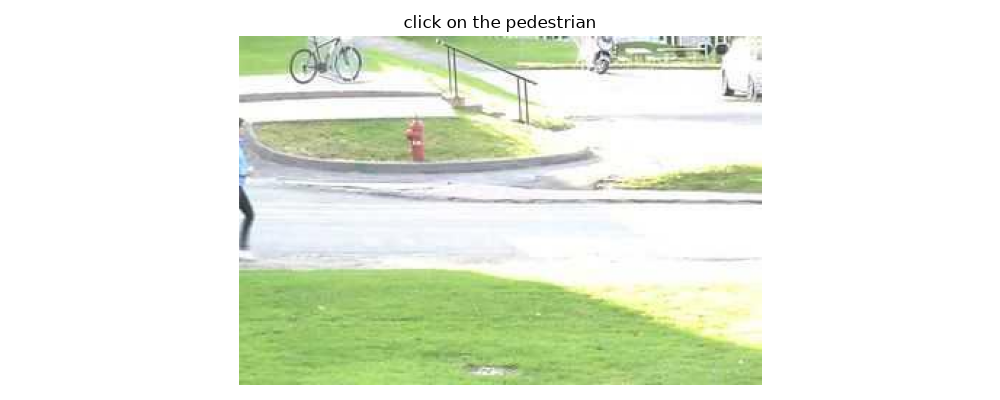

In [5]:
#frame where we click
frame = 0
click_image = io.imread(f"{FRAMES_dir}/{frame}.jpg")

#we receive from imshow the fig and the axeslist
fig, axeslist = imshow(click_image, "click on the pedestrian")
ax = axeslist[0,0] #box inside the window where the image is drawn

#function called automatically every time we click 
#event : information about the click
def on_click(event): 
    #position :
    x = int(event.xdata)
    y = int(event.ydata)

    #draw where we clicked
    ax.plot(x,y, "r+", markersize=15)
    #write small title with the position
    ax.set_title(f"click: x={x}, y={y}")

    #save click in file
    click = {"frame": frame, "x":x, "y":y}
    with open(CLICK_file, "w") as f : 
        json.dump(click, f) #write python data in json file

fig.canvas.mpl_connect("button_press_event", on_click)

## Load SAM 2 

In [6]:
#gpu, mac gpu or cpu
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device :", device)

#build predictor
predictor = build_sam2_video_predictor(CONFIG, CHECKPOINT, device=device)

#read all frames and keeps memory for the video
state = predictor.init_state(video_path=FRAMES_dir, offload_video_to_cpu=True)
print("frames loaded :", state["num_frames"])

device : cuda


frame loading (JPEG): 100%|██████████| 100/100 [00:02<00:00, 39.81it/s]


frames loaded : 100


## Click to mask

pixels in the mask : 582


/home/rachid/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/home/rachid/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(


(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'object in red'}>,
         <Axes: title={'center': 'mask'}>]], dtype=object))

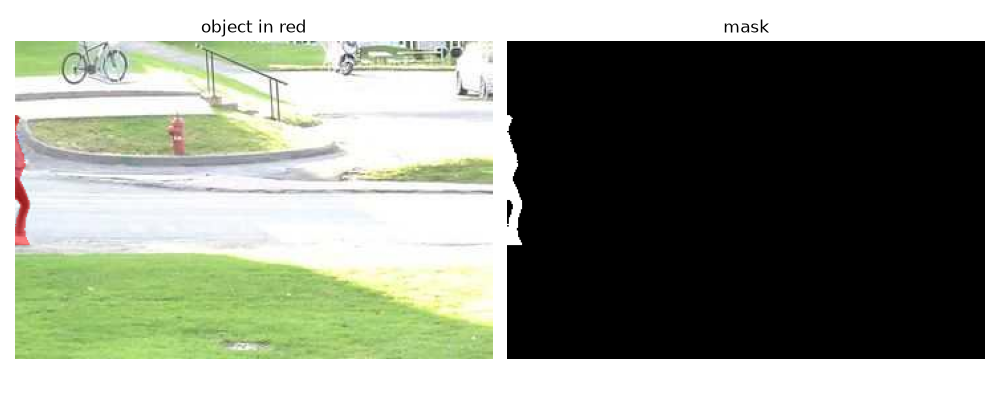

In [7]:
def add_click(click_file, positive=True, reset=True):
    #reset=True: forget previous clicks
    #reset=False: add a correction click on top of the previous ones
    #positive=True : "this is the object", False : "this is NOT the object"
    if reset:
        predictor.reset_state(state)

    with open(click_file) as f:
        click = json.load(f)

    points = np.array([[click["x"], click["y"]]], dtype=np.float32)
    labels = np.array([1 if positive else 0], dtype=np.int32)

    _, _, mask_scores = predictor.add_new_points_or_box(state, frame_idx=click["frame"], obj_id=1, points=points, labels=labels,)

    #score > 0 means "object"
    mask = (mask_scores[0, 0] > 0).cpu().numpy()
    return mask, click


mask, click = add_click(CLICK_file)
print("pixels in the mask :", mask.sum())
imshow([red_overlay(load_frame(click["frame"]), mask), mask * 255], ["object in red", "mask"])

## Follow the object

In [8]:
masks = {}

for frame_idx, obj_ids, mask_scores in predictor.propagate_in_video(state):
    masks[frame_idx] = (mask_scores[0,0] > 0).cpu().numpy()

print("masks: ", len(masks))

propagate in video:   0%|          | 0/100 [00:00<?, ?it/s]

/home/rachid/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/home/rachid/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 100/100 [00:34<00:00,  2.91it/s]

masks:  100


## Load masks

In [9]:
#start from an empty folder
shutil.rmtree(MASKS_dir, ignore_errors=True)
os.makedirs(MASKS_dir)

#save each mask: True = object
for i, mask in masks.items():
    np.save(f"{MASKS_dir}/{i}.npy", mask)

print("masks saved :", len(os.listdir(MASKS_dir)))

masks saved : 100


## Verify + red frames

video saved


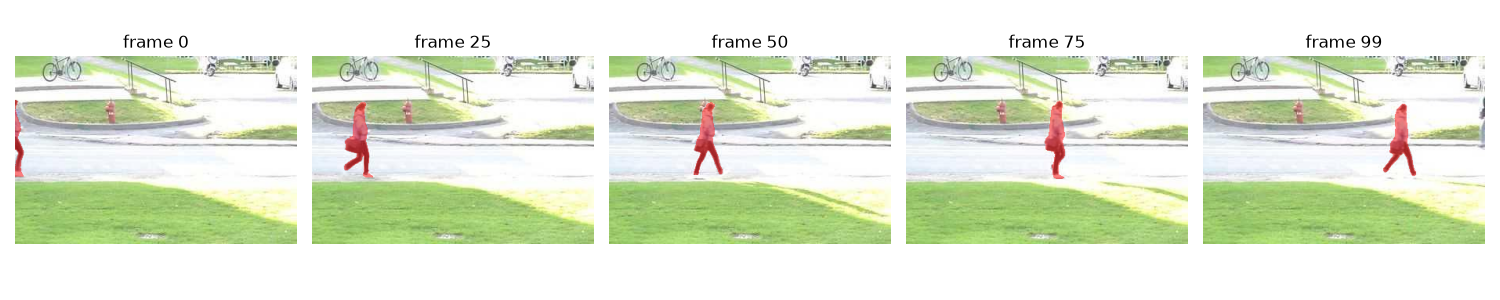

In [10]:
#object in red on every frame
red_frames = [red_overlay(load_frame(i), masks[i]) for i in range(len(masks))]

#look at 5 frames to verify
n = len(red_frames)
check = [0, n // 4, n // 2, 3 * n // 4, n - 1]
imshow([red_frames[i] for i in check], [f"frame {i}" for i in check], figsize=(15, 3))

#save the video
os.makedirs(OUTPUTS_dir, exist_ok=True)
save_video(red_frames, f"{OUTPUTS_dir}/red.mp4", fps=30)
print("video saved")